# Individual homework project 1

In [3]:
# Import modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import sys
print(sys.executable)

c:\Users\kelly\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [6]:
# Import data
customers = pd.read_csv("../../Data/customers.csv")
transactions = pd.read_csv("../../Data/transactions.csv")
web_sessions = pd.read_csv("../../Data/web_sessions.csv")
campaigns = pd.read_csv("../../Data/campaign_touchpoints.csv")

### Specific questions

Q1. What is the average purchase value for customers from Spain?

In [7]:

transactions.head()

,transaction_id,customer_id,product_category,purchase_value,discount_used,purchase_date,is_refunded,refund_date,refund_reason
0,1,8141,home,380.95,0,2023-09-05,0,NaN,NaN
1,2,1297,fashion,67.08,0,2019-08-07,0,NaN,NaN
2,3,7930,toys,43.37,1,2020-02-07,1,1.581898e+18,late_delivery
3,4,2426,electronics,1191.45,0,2020-10-02,0,NaN,NaN
4,5,6614,fashion,112.21,0,2023-09-15,0,NaN,NaN


In [8]:
customers.head()

,customer_id,age,gender,country,acquisition_channel,signup_date,customer_status,loyalty_tier,campaign_id,last_active_date
0,1,56.0,Other,Germany,referral,2019-07-21,one_time,none,183,2021-04-06
1,2,38.0,Other,Netherlands,email,2022-03-04,churned,none,548,2024-11-27
2,3,28.0,Other,Australia,referral,2024-05-21,repeat,bronze,37,2025-01-07
3,4,19.0,Female,Australia,paid_search,2022-06-28,repeat,bronze,14,2024-03-20
4,5,38.0,Female,Australia,referral,2024-07-17,one_time,none,635,2024-11-12


In [12]:
# Insert code here
# Average purchase value for customers in Spain
cust_trans_merged = pd.merge(customers, transactions, on="customer_id")
#cust_trans_merged.groupby("country")["purchase_value"].mean()
cust_trans_merged[cust_trans_merged["country"] == "Spain"]["purchase_value"].mean()


np.float64(230.95889872521244)

Q2. What is the minimum purchase value for customers from Germany?

In [14]:
# minimum purchase value for customers in Germany
cust_trans_merged[cust_trans_merged["country"] == "Germany"]["purchase_value"].min()


np.float64(10.01)

Q3. How much did males spend on buying products in the Sports category?

In [17]:
# Total purchase value for male customers who purchased sports products
cust_trans_merged[(cust_trans_merged["gender"] == "Male") & (cust_trans_merged["product_category"] == "sports")]["purchase_value"].sum()


np.float64(404877.87)

Q4. What is the average age of female customers from Canada?

In [28]:
# Average age of female customers fom Canada
customers[(customers["gender"] == "Female") & (customers["country"] == "Canada")]["age"].mean()

np.float64(42.9168765743073)

Q5. How much does an average male customer from the UK spend?

In [21]:
#  Average purchase value for male customers from the UK
cust_trans_merged[(cust_trans_merged["gender"] == "Male") & (cust_trans_merged["country"] == "UK")]["purchase_value"].mean()

np.float64(234.4815730932203)

Q6. What is the maximum purchase value for females in the Toys category?

In [25]:
# Maximum purchase value for female customers who purchased toys
cust_trans_merged[(cust_trans_merged["gender"] == "Female") & (cust_trans_merged["product_category"]=="toys")]["purchase_value"].max()

np.float64(79.99)

Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [27]:

web_sessions["converted"].unique()

array([0, 1])

In [31]:
# Average number of pages viewed by customers who converted
# sessions_trans_merged = pd.merge(web_sessions, transactions, on="customer_id")
web_sessions[(web_sessions["converted"]==1)]["pages_viewed"].mean()
# sessions_trans_merged = pd.merge(web_sessions, transactions, on="customer_id")

np.float64(5.728619675345898)

Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [32]:
# Average time spend on the site for purchasing vs non-purchasing customers
web_sessions.groupby(["converted"])["time_on_site"].mean()

converted
0    299.238547
1    311.194837
Name: time_on_site, dtype: float64

### Visualisation tasks

Q9. Plot purchasing value across years.

In [ ]:
# Conversion of purchase_date to year
transactions["year"] = transactions["purchase_date"].dt.year

In [34]:
transactions.columns

Index(['transaction_id', 'customer_id', 'product_category', 'purchase_value',
       'discount_used', 'purchase_date', 'is_refunded', 'refund_date',
       'refund_reason', 'year'],
      dtype='str')

In [1]:
# DataFrame: Total purchase value for each year
purchase_by_year = transactions.groupby("year")["purchase_value"].sum().reset_index()
print(purchase_by_year)

NameError: name 'transactions' is not defined

In [44]:
purchase_by_year.head()

,year,purchase_value
0,2019,1753046.60
1,2020,1755373.82
2,2021,1723096.74
3,2022,1821268.82
4,2023,1757793.75


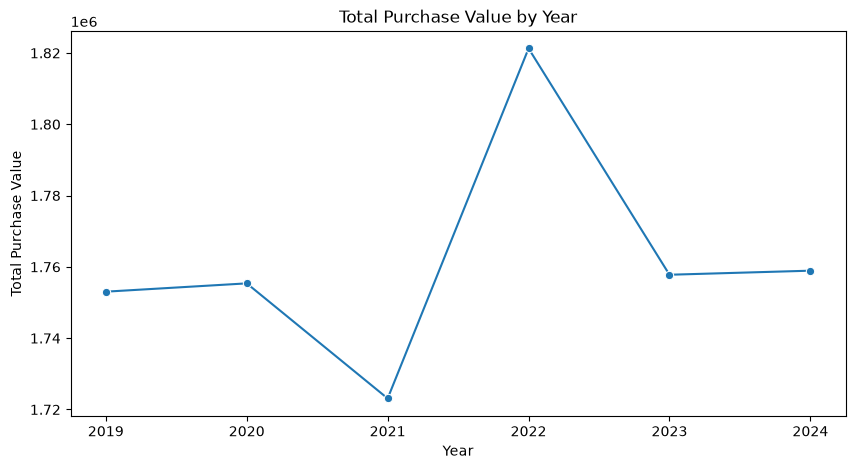

In [62]:
# plot purchasing value across years
figure = plt.figure(figsize=(10,5))
sns.lineplot(data=purchase_by_year, x="year", y="purchase_value", marker="o")
plt.title("Total Purchase Value by Year")
plt.xlabel("Year")
plt.ylabel("Total Purchase Value")
plt.show()


Q10. Plot purchasing value across product categories.

In [49]:
#DataFrame: Total purchase value for each product category
total_purchase_by_product_category = transactions.groupby("product_category")["purchase_value"].sum().reset_index()
print(total_purchase_by_product_category)

  product_category  purchase_value
0           beauty      1218918.23
1      electronics      5020188.13
2          fashion       759966.11
3             home      2022597.38
4           sports      1210881.70
5             toys       336960.71


[]

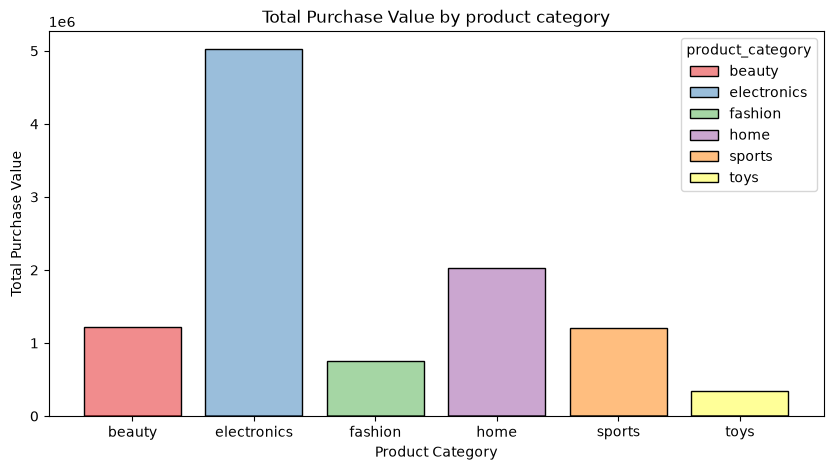

In [56]:
# plot total purchase value by product category
figure = plt.figure(figsize=(10,5))
sns.histplot(data=total_purchase_by_product_category, x="product_category", weights="purchase_value", bins=len(total_purchase_by_product_category), discrete=True, shrink=0.8, hue="product_category", palette="Set1")
plt.title("Total Purchase Value by product category")
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Value")
plt.plot()

### Free exercise

Explore the transactions dataset and:

- Create two visualisations of your choice
- Identify three patterns in the data
- Write five insights in plain English explaining what the data tells us

Your insights should focus on behaviour, spending patterns, or conversion

In [59]:
# Visualisation 1: Purchase value by product category and by year
purchase_by_year_product_category = transactions.groupby(["year", "product_category"])["purchase_value"].sum().reset_index()
print(purchase_by_year_product_category)

    year product_category  purchase_value
0   2019           beauty       209104.55
1   2019      electronics       828526.23
2   2019          fashion       124341.60
3   2019             home       328884.75
4   2019           sports       201930.16
5   2019             toys        60259.31
6   2020           beauty       207789.45
7   2020      electronics       816438.58
8   2020          fashion       125886.88
9   2020             home       341794.11
10  2020           sports       206236.36
11  2020             toys        57228.44
12  2021           beauty       194040.86
13  2021      electronics       819921.86
14  2021          fashion       124671.86
15  2021             home       323469.65
16  2021           sports       203740.95
17  2021             toys        57251.56
18  2022           beauty       213168.38
19  2022      electronics       874446.44
20  2022          fashion       130425.92
21  2022             home       355077.96
22  2022           sports       19

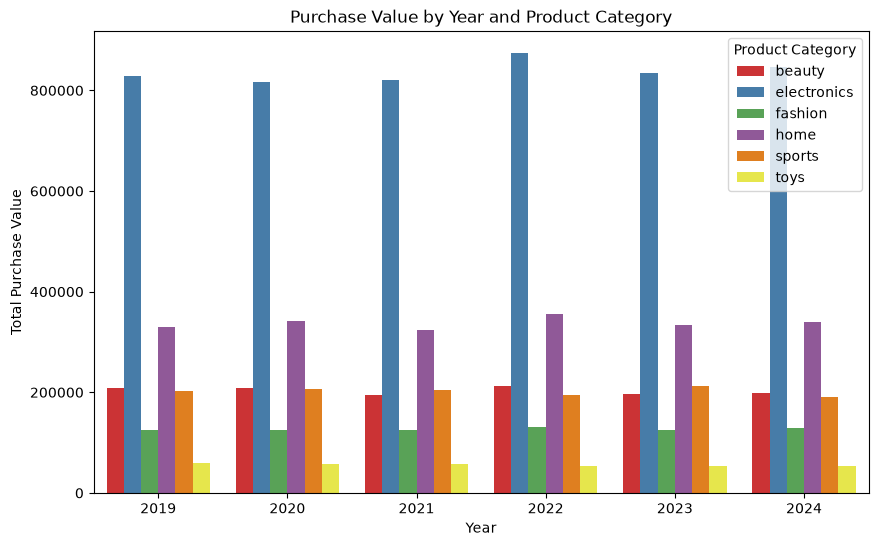

In [65]:
plt.figure(figsize=(10,6))
sns.barplot(data=purchase_by_year_product_category, x="year", y="purchase_value", hue="product_category", palette="Set1")
plt.xlabel("Year")
plt.ylabel("Total Purchase Value")
plt.title("Purchase Value by Year and Product Category")
plt.legend(title="Product Category")
plt.show()


In [67]:
# Visualisation 2: Disount used by product category and by year
transacttions_discounted = transactions[transactions["discount_used"]==1]
discount_by_year_product_category = transacttions_discounted.groupby(["year", "product_category"])["discount_used"].sum().reset_index()
print(discount_by_year_product_category)

    year product_category  discount_used
0   2019           beauty            389
1   2019      electronics            361
2   2019          fashion            375
3   2019             home            382
4   2019           sports            396
5   2019             toys            384
6   2020           beauty            411
7   2020      electronics            353
8   2020          fashion            393
9   2020             home            387
10  2020           sports            385
11  2020             toys            386
12  2021           beauty            376
13  2021      electronics            371
14  2021          fashion            371
15  2021             home            346
16  2021           sports            380
17  2021             toys            391
18  2022           beauty            358
19  2022      electronics            420
20  2022          fashion            371
21  2022             home            398
22  2022           sports            382
23  2022        

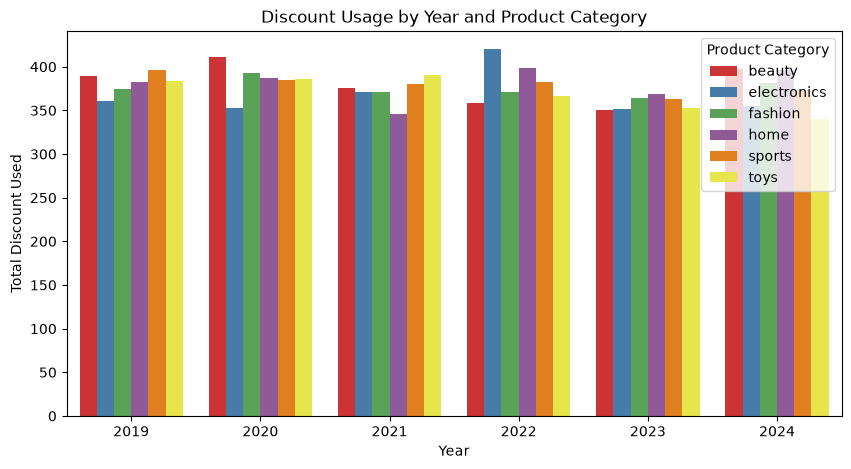

In [68]:
plt.figure(figsize=(10,5))
sns.barplot(data=discount_by_year_product_category, x="year", y="discount_used", hue="product_category", palette="Set1")
plt.xlabel("Year")
plt.ylabel("Total Discount Used")
plt.title("Discount Usage by Year and Product Category")
plt.legend(title="Product Category")
plt.show()


## Patterns
- Electronics have the highest purchase value every year, making it the strongest product category in terms of revenue generated, follow by home products. Toys have the lowest total purchase value.
- 2022 has the highest total purchase value, while 2021 has the lowest total purchase value.
- The number of transactions using discount varies across product category.

## Insights
1- Electronics perform strongly over time: this suggest that customers spend more on electronics than other product categories. Electronics is therefore an important category for business.

2- Toys generate the lowest total purchase value, suggesting that customer spending on toys is much lower than customer spending on other product categories.

3- Overall sales peaked in 2022, this suggest that 2022 was the strongest year for sales. Sales were lowest in 2021, this may have been influenced by economic conditions or others events.

4- Discounts are more used in some product categories than others. This suggest that some promotional strategies may be more important for certain product categories.

5- A product category with the highest total number of sales does not necessarily have highest total number of discount used. This suggest that discount usage is not the only factor influencing customer spending.


In [74]:
refund = transactions.groupby("refund_reason")["purchase_value"].mean().reset_index()
print(refund)

   refund_reason  purchase_value
0   changed_mind      235.244904
1        damaged      236.705523
2  late_delivery      239.862210
3     wrong_item      231.080240


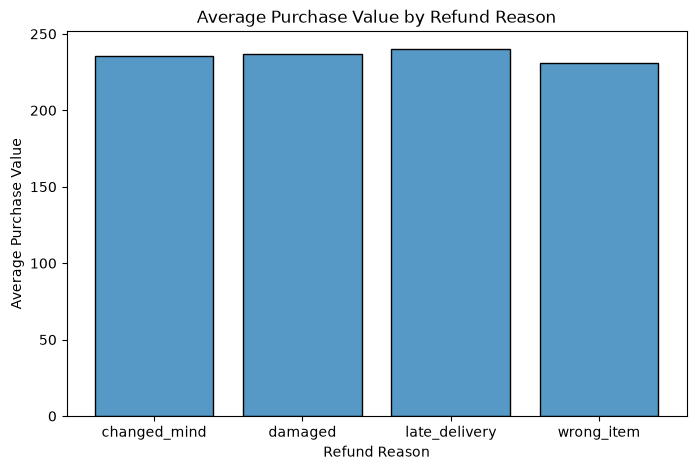

In [79]:
plt.figure(figsize=(8,5))
sns.histplot(data=refund, x="refund_reason", weights="purchase_value", bins=len(refund), discrete=True, shrink=0.8)
plt.xlabel("Refund Reason")
plt.ylabel("Average Purchase Value")
plt.title("Average Purchase Value by Refund Reason")
plt.show()